# Analiza danych przestrzennych - ćwiczenia laboratoryjne 2026/2027

Ten notatnik zalicza się do grupy zestawów zadań, na podstawie których odbywa się zaliczenie ćwiczeń i podlega zwrotowi do oceny w ustalonym na zajęciach terminie.

### Zasady uzupełniania i oceny notatnika
Uwagi i wytyczne ogólne dotyczące uzupełniania i oceny notatnika:
- Podczas wykonywania zadań należy korzystać wyłącznie z pakietów zaimportowanych na początku notatnika oraz z pakietów wchodzących w skład standardowej biblioteki Pythona, które można zaimportować samodzielnie we wskazanej komórce notatnika.
- Swoje rozwiązania należy wprowadzać wyłącznie w miejsce następujących fragmentów kodu:<br/> `# YOUR CODE HERE`<br/> `raise NotImplementedError()`<br/> 
a odpowiedzi tekstowe w komórkach oznaczonych hasłem:<br/> 
`YOUR ANSWER HERE`<br/> 
Nie należy w żaden sposób modyfikować pozostałych fragmentów kodu oraz innych elementów notatnika, w szczególności dodawać lub usuwać komórek oraz zmieniać nazwy pliku.
- Jeżeli zestaw zadań wymaga skorzystania z fragmentów kodu opracowanego w ramach wcześniejszych zestawów zadań, należy je umieścić we wskazanej komórce notatnika.
- Otrzymywane wyniki i odpowiedzi mają być rezultatem wykonania napisanego kodu, odpowiedzi uzupełniane manualnie nie podlegają ocenie.
- Zawarte w notatniku automatyczne testy mają charakter poglądowy. Dotyczą one wybranych aspektów zadań i mają na celu wykrywać podstawowe błędy. Przejście przez kod wszystkich testów nie oznacza, że zadanie jest wykonane w całości poprawnie i zostanie ocenione na maksymalną liczbę punktów.
- W przypadku wystąpienia ostrzeżenia należy przeanalizować jego przyczynę i odpowiednio poprawić kod. Nie należy wyciszać ostrzeżeń w celu ukrycia problemów w rozwiązaniu.
- Zadania, których rozwiązania powodują błędy przerywające wykonywanie kodu, nie podlegają ocenie.
- W treści niektórych zadań mogą znaleźć się przykładowe schematy ich rozwiązania lub przykładowe schematy istotnych części rozwiązania. Nie zawsze są to rozwiązania optymalne pod kątem długości kodu lub prostoty rozwiązania. Ich celem jest klarowne rozbicie pracy na kroki i ułatwienie samodzielnej weryfikacji wyników na każdym etapie. Należy je traktować wyłącznie poglądowo, a nie jako jedyne dopuszczalne rozwiązania. Ocenie podlega poprawność merytoryczna rozwiązania, jego kompletność oraz zgodność z wymaganiami, a nie konkretna forma zapisu.
- Dla zachowania przejrzystości i łatwego odnajdywania informacji w treści zadań podawane są pełne nazwy funkcji, metod i klas wraz z nazwami pakietów (np. `pandas.read_csv()`, `geopandas.GeoDataFrame.to_crs()`). W notatniku te same obiekty są dostępne przez skrótowe aliasy (np. `pd.read_csv()`, `gpd.GeoDataFrame.to_crs()`).

### Zasady wizualizacji wyników
Uwagi i wytyczne ogólne dotyczące wizualizacji wyników:
- Wszystkie wykresy powinny być wykonane w jednolitym, przejrzystym i czytelnym stylu, posiadać odpowiednio dobrane proporcje i zakresy wartości osi.
- Figury oraz obszary wykresów powinny mieć białe tło. Kolory napisów i pozostałych elementów należy dobrać tak, aby były czytelne na tym tle. Szerokość figury nie powinna przekraczać 20 cali.
- Każdy wykres powinien mieć tytuł. Osie powinny mieć opisy określające przedstawiane wielkości oraz ich jednostki, jeżeli mają zastosowanie. Jeżeli figura zawiera kilka wykresów, powinna mieć również wspólny tytuł. W przypadku map można wyłączyć widoczność osi zamiast je opisywać.

### Przed odesłaniem zestawu zadań do oceny
Przed odesłaniem zestawu zadań do oceny proszę uzupełnić komórkę z danymi autorów rozwiązania (nazwa zespołu oraz imiona, nazwiska i numery indeksów członków zespołu) oraz upewnić się, że notatnik działa zgodnie z oczekiwaniami. W tym celu należy skorzystać z opcji **Restart Kernel and Run All Cells...** dostępnej na górnej belce notatnika pod symbolem $\blacktriangleright\blacktriangleright$.

**Nazwa zespołu:** …

**Członkowie zespołu - imiona, nazwiska i numery indeksów:**

- …
- …
- …

---

## Zestaw zadań 3: Łączenie i analiza wektorowych warstw przestrzennych (część 1)

In [68]:
import numpy as np
import pandas as pd
import scipy as sp
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd
import contextily as cx
import shapely as shp
import networkx as nx

In [69]:
# Miejsce do importu pakietów wchodzących w skład standardowej biblioteki Pythona oraz ustawienie opcji wykorzystywanych pakietów

### Wczytanie danych

Poniższy kod wczytuje do zmiennych `rivers`, `cities`, `districts` oraz `voivodeships` dane z pliku `ZZ03_data.gpkg`.

Aby poprawnie wczytać dane, umieść plik `ZZ03_data.gpkg` w tym samym folderze, w którym znajduje się notatnik.

Dane są zapisane w układzie odniesienia EPSG:2180 i obejmują:

- `rivers` - geometrie liniowe wybranych ważniejszych rzek,
- `cities` - punktowe lokalizacje miast,
- `districts` - geometrie poligonowe powiatów,
- `voivodeships` - geometrie poligonowe województw.

In [70]:
rivers = gpd.read_file("ZZ03_data.gpkg", layer="rivers")
cities = gpd.read_file("ZZ03_data.gpkg", layer="cities")
districts = gpd.read_file("ZZ03_data.gpkg", layer="districts")
voivodeships = gpd.read_file("ZZ03_data.gpkg", layer="voivodeships")

### Uwagi dotyczące funkcji `geopandas.sjoin()` i `geopandas.sjoin_nearest()`

Funkcje te łączą informacje z dwóch tablic `geopandas.GeoDataFrame` na podstawie położenia ich geometrii.

#### Łączenie przestrzenne przez `geopandas.sjoin()`
- Argument `predicate` określa relację przestrzenną wykorzystywaną do połączenia, np. położenie obiektów z pierwszej tablicy z obiektami w drugiej tablicy w granicach których się znajdują.
- Argument `how` określa sposób łączenia tablic oraz wybór zachowywanej kolumny geometrii:
  - `"left"` - złączenie lewostronne: zachowuje wszystkie obiekty lewej tablicy oraz jej geometrie, niezależnie od znalezionych dopasowań w prawej tablicy.
  - `"right"` - złączenie prawostronne: zachowuje wszystkie obiekty prawej tablicy oraz jej geometrie, niezależnie od znalezionych dopasowań w lewej tablicy.
  - `"inner"` - złączenie wewnętrzne: zachowuje wyłącznie dopasowane pary obiektów oraz geometrie lewej tablicy.
- Jeden obiekt może mieć wiele dopasowań, dlatego może występować w wyniku wielokrotnie. Obiekty bez dopasowania, w zależności od wybranego trybu połączenia, nie są uwzględniane w tablicy lub brakujące atrybuty są oznaczane jako `NaN`. Wynik nie musi zachowywać unikalnych indeksów.
- Kierunek relacji ma znaczenie: warunek jest sprawdzany dla geometrii lewej tablicy względem geometrii prawej.

#### Łączenie z najbliższym obiektem przez `geopandas.sjoin_nearest()`
- Funkcja wskazuje obiekty drugiej tablicy znajdujące się w najmniejszej odległości od geometrii pierwszej tablicy. Jeśli kilka obiektów znajduje się w tej samej najmniejszej odległości, funkcja może zwrócić kilka wierszy dla jednego obiektu. Możliwe jest również wykluczenie dopasowania do geometrycznie identycznych obiektów.
- Argument `how` działa analogicznie jak w `geopandas.sjoin()`, określając, które obiekty zostaną zachowane w wyniku.
- Kierunek relacji ma znaczenie: warunek jest sprawdzany dla geometrii lewej tablicy względem geometrii prawej.

### Zadanie 1: Łączenie przestrzenne miast i powiatów (10 pkt)

#### a) Przypisanie miast do powiatów

Korzystając z funkcji `geopandas.sjoin()`, przygotuj i wyświetl tablicę `cities_within_districts`, w której każdemu miastu przypisany jest powiat, w którym się znajduje.

Tablica `cities_within_districts`:
> Indeks:<br>
> Indeksy miast z tablicy `cities`.

> Kolumny: miasto, powiat, indeks powiatu, geometry<br>
> Kolumny zawierają nazwy miast, nazwy powiatów, w których znajdują się miasta, indeksy tych powiatów z tablicy `districts` oraz geometrie miast.

Przykładowy schemat rozwiązania:
1) Połącz tablicę `cities` z kolumnami `powiat` i `geometry` tablicy `districts` funkcją `geopandas.sjoin()`. Dobierz argumenty `how` i `predicate` tak, aby zachować wszystkie miasta i przypisać im powiaty, w których leżą.
2) Korzystając z funkcji `pandas.DataFrame.rename()`, zmień nazwę kolumny z indeksem prawej tablicy na `indeks powiatu`.
3) Ustaw kolumny tablicy w wymaganej kolejności.
4) Wyświetl tablicę.

In [71]:
cities_within_districts = gpd.sjoin( cities, districts, how = "left", predicate = "within" )
cities_within_districts.rename( columns={"index_right" : "indeks powiatu"}, inplace = True )
cities_within_districts = cities_within_districts[["miasto", "powiat", "indeks powiatu", "geometry"]]
cities_within_districts

,miasto,powiat,indeks powiatu,geometry
0,Aleksandrów Kujawski,aleksandrowski,30,POINT (479369.11 556829.57)
1,Aleksandrów Łódzki,zgierski,110,POINT (520933.24 439273.37)
2,Alwernia,chrzanowski,117,POINT (538609.78 243752.61)
3,Andrychów,wadowicki,132,POINT (524250.26 220924.61)
4,Annopol,kraśnicki,59,POINT (700882.43 339274.19)
...,...,...,...,...
1021,Żukowo,kartuski,237,POINT (458701.17 720352.32)
1022,Żuromin,żuromiński,172,POINT (560942.38 578213.27)
1023,Żychlin,kutnowski,92,POINT (542728.02 486627.65)
1024,Żyrardów,żyrardowski,173,POINT (599173.26 466546)


In [72]:
# Komórka testowa
assert type(cities_within_districts) == gpd.GeoDataFrame, "Zmienna cities_within_districts powinna zawierać GeoDataFrame."
assert cities_within_districts.shape == (1026, 4), "Niepoprawna liczba miast lub kolumn."
assert list(cities_within_districts.columns) == ["miasto", "powiat", "indeks powiatu", "geometry"], "Niepoprawne nazwy lub kolejność kolumn."
assert cities_within_districts.crs == "epsg:2180", "Geometrie powinny być wyrażone w EPSG:2180."
assert cities_within_districts.index.equals(cities.index), "Niezachowana kolejność miast z wejściowej tablicy"
assert cities_within_districts["indeks powiatu"].isin(districts.index).all(), "Nie wszystkim miastom przypisano poprawny indeks powiatu."
assert np.array_equal(cities_within_districts["powiat"], districts.loc[cities_within_districts["indeks powiatu"], "powiat"]), "Nazwy powiatów nie odpowiadają ich indeksom."
assert cities_within_districts.geometry.geom_equals(cities.geometry).all(), "Zachowaj oryginalne geometrie miast."

#### b) Liczba miast w powiatach

Korzystając z tablicy `cities_within_districts`, określ liczbę miast znajdujących się w poszczególnych powiatach. Zapisz wyniki w kolumnie `liczba miast` tablicy `districts`, przyjmując 0 dla powiatów bez miast. Następnie:
- zapisz maksymalną liczbę miast w powiecie do zmiennej `number_of_cities`, a nazwę odpowiedniego powiatu do zmiennej `district_with_most_cities`,
- wyświetl wyniki pełnym zdaniem za pomocą funkcji `print()` (który powiat ma najwięcej miast i ile ich w nim jest) i przygotuj mapę powiatów pokolorowanych według liczby miast.

Wizualizacja powinna zawierać:
- powiaty wypełnione kolorem powiązanym z liczbą miast w ich obrębie (ciągła skala barw) oraz słupek skali barw,
- punkty miast w wyróżniającym się kolorze,
- pogrubione granice województw, bez wypełnienia.

Przygotuj figurę zgodnie z wytycznymi z nagłówka notatnika. Ustaw parametry wykresu oraz wizualizowanych obiektów (wielkość figury, kolory, grubość linii, wielkość punktów itp.) tak, aby wygenerowana mapa była przejrzysta i czytelna.

Przykładowy schemat rozwiązania:
1) Korzystając z funkcji `pandas.Series.value_counts()`, policz wystąpienia powiatów w tablicy `cities_within_districts`. Zliczaj miasta według indeksów powiatów, a nie ich nazw, aby nie łączyć różnych powiatów o tej samej nazwie.
2) Korzystając z funkcji `pandas.Series.reindex()`, dopasuj wyniki do indeksu tablicy `districts`, uzupełniając brakujące wartości zerami. Zapisz liczby całkowite do kolumny `liczba miast`.
3) Korzystając z funkcji `pandas.Series.idxmax()` i `pandas.DataFrame.loc`, znajdź powiat z największą liczbą miast i zapisz wymagane wyniki.
4) Wyświetl wyniki zgodnie z instrukcją i przygotuj mapę.

In [73]:
liczba_miast = cities_within_districts["indeks powiatu"].value_counts().reindex(  districts.index, 
                                                                                                            fill_value = 0 )
districts["liczba miast"] = liczba_miast.astype( int )
districts 
max = districts["liczba miast"].idxmax()
print(districts.iloc[7])
number_of_cities = 11
district_with_most_cities = "kłodzki"
print( f" Powiatem o maksymalnej liczbie miast jest powiat {district_with_most_cities}. Posiada on {number_of_cities} miast. ")

TERYT                                                        0208
powiat                                                    kłodzki
geometry        MULTIPOLYGON (((348008.730118411 284479.349724...
liczba miast                                                   11
Name: 7, dtype: object
 Powiatem o maksymalnej liczbie miast jest powiat kłodzki. Posiada on 11 miast. 


In [74]:
# Komórka testowa
assert "liczba miast" in districts.columns, "W tablicy districts brakuje kolumny liczba miast."
assert pd.api.types.is_integer_dtype(districts["liczba miast"]), "Liczby miast powinny być całkowite."
assert districts["liczba miast"].ge(0).all(), "Liczby miast nie mogą być ujemne."
assert districts["liczba miast"].sum() == 1026, "Suma miast w powiatach jest niepoprawna."
assert districts.loc[districts["powiat"].eq("suwalski"), "liczba miast"].iloc[0] == 0, "Powiat suwalski powinien mieć zero miast."
assert sorted(districts.loc[districts["powiat"].eq("świdnicki"), "liczba miast"]) == [2, 5], "Nie łącz powiatów o tej samej nazwie."
assert np.array_equal(districts["liczba miast"], cities_within_districts["indeks powiatu"].value_counts().reindex(districts.index, fill_value=0)), "Niepoprawna liczba miast przypisana do powiatów."
assert number_of_cities == 11 and district_with_most_cities == "kłodzki", "Niepoprawnie wskazano powiat z największą liczbą miast."

Text(0.5, 1.0, 'Powiaty z uwzględnieniem liczby miast w danym powiecie')

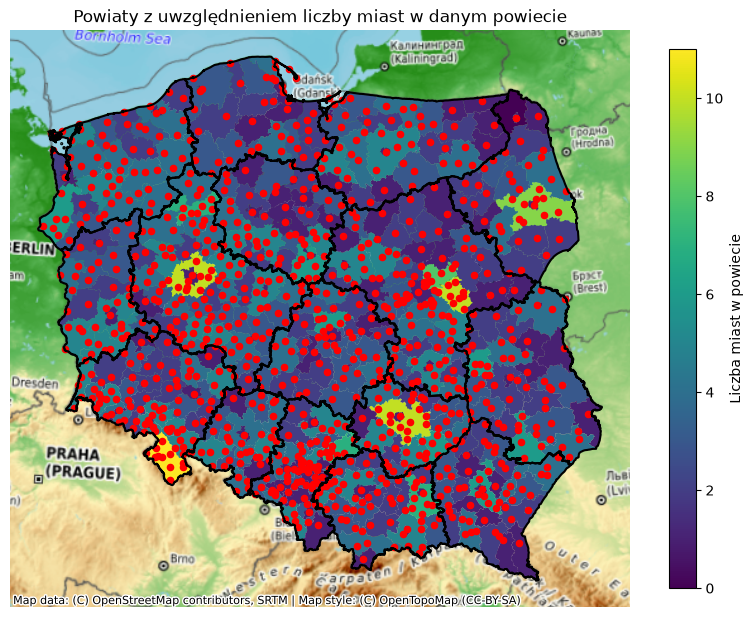

In [75]:
fig, ax = plt.subplots( 1,1, figsize = (10,10))
districts.plot( ax = ax, column = "liczba miast" ,legend = True, cmap = "viridis", legend_kwds = { "label" : "Liczba miast w powiecie", 
                                                                         "orientation" : "vertical", "shrink": 0.7  } )
cities.plot(ax = ax, color = "red", markersize = 20 )
voivodeships.boundary.plot( ax = ax, color = "black" )
cx.add_basemap( ax = ax, source = "OpenTopoMap", crs = "EPSG:2180" )
ax.set_axis_off()
ax.set_title( "Powiaty z uwzględnieniem liczby miast w danym powiecie" )

### Zadanie 2: Najbliższa rzeka (8 pkt)

Korzystając z funkcji `geopandas.sjoin_nearest()`, przygotuj tablicę `cities_nearest_river`, w której każdemu miastu przypisana jest bliższa z dwóch rzek: Wisła lub Odra.

Tablica `cities_nearest_river`:
> Indeks:<br>
> Indeksy miast z tablicy `cities`.

> Kolumny: miasto, bliższa rzeka, odległość od rzeki, geometry<br>
> Kolumny zawierają nazwy miast, nazwy bliższych rzek (Wisła lub Odra), odległości miast od bliższych rzek wyrażone w metrach oraz geometrie miast.

Następnie:
- zapisz liczby miast przypisanych do Wisły i Odry do zmiennych `cities_nearest_vistula` oraz `cities_nearest_oder`,
- zapisz nazwę miasta najdalej położonego od bliższej z tych rzek do zmiennej `farthest_city`,
- wyświetl wyniki pełnymi zdaniami za pomocą `print()` (dla ilu miast bliższą z rzek jest Wisła, a dla ilu Odra; które miasto leży najdalej od bliższej z tych rzek) i przygotuj mapę miast według przypisanej rzeki.

Wizualizacja powinna zawierać:
- granice województw, bez wypełnienia,
- Wisłę i Odrę w wyróżniającym się kolorze,
- punkty miast w jednym z dwóch kolorów, zależnie od przypisanej rzeki,
- legendę wskazującą bliższą rzekę (objaśnienie kolorów wykorzystanych do oznaczenia miast).

Przygotuj figurę zgodnie z wytycznymi z nagłówka notatnika. Ustaw parametry wykresu oraz wizualizowanych obiektów (wielkość figury, kolory, grubość linii, wielkość punktów itp.) tak, aby wygenerowana mapa była przejrzysta i czytelna.

Przykładowy schemat rozwiązania:
1) Wybierz z tablicy `rivers` Wisłę i Odrę (przydatna może być selekcja logiczna po kolumnie atrybutowej, operatory `pandas.DataFrame.loc`, `pandas.DataFrame.iloc` oraz funkcja `pandas.Series.isin()`).
2) Połącz miasta z wybranymi rzekami funkcją `geopandas.sjoin_nearest()`, zachowując wszystkie miasta i zapisując odległości do kolumny `odległość od rzeki`.
3) Usuń zbędne kolumny, nadaj pozostałym wymagane nazwy i ustaw kolumny tablicy `cities_nearest_river` w odpowiedniej kolejności.
4) Policz miasta przypisane do każdej rzeki, a za pomocą `pandas.Series.idxmax()` oraz własności `pandas.DataFrame.loc` wyznacz miasto o największej odległości od bliższej rzeki.
5) Wyświetl wyniki zgodnie z instrukcją i przygotuj mapę.

In [76]:
Wisła = rivers[rivers["rzeka"] == "Wisła" ]
Odra = rivers[rivers["rzeka"] == "Odra" ] 
selected_rivers = rivers.loc[
    rivers["rzeka"].isin(["Wisła", "Odra"])
]
selected_rivers
cities_nearest_river = gpd.sjoin_nearest( cities, selected_rivers, how = "left",  distance_col="odległość od rzeki" )
#cities_nearest_river.head(50)
cities_nearest_river.rename( columns = { "rzeka" : "bliższa rzeka" }, inplace = True ) 
cities_nearest_river = cities_nearest_river[["miasto", "bliższa rzeka", "odległość od rzeki", "geometry" ]] 

cities_nearest_vistula = ( cities_nearest_river["bliższa rzeka"] == "Wisła" ).sum()
cities_nearest_oder = ( cities_nearest_river["bliższa rzeka"] == "Odra" ).sum()
cities_nearest_vistula 
max_ = cities_nearest_river["odległość od rzeki"].idxmax()
max_
farthest_city = cities_nearest_river.iloc[713]
farthest_city = farthest_city.iloc[0]
farthest_city
print(f" Wisła jest rzeką bliższą dla {cities_nearest_vistula} miast, a Odra dla {cities_nearest_oder} miast. Miasto, które leży najdalej od bliższej z tych rzek to: {farthest_city}") 



 Wisła jest rzeką bliższą dla 690 miast, a Odra dla 336 miast. Miasto, które leży najdalej od bliższej z tych rzek to: Sejny


In [77]:
# Komórka testowa
assert type(cities_nearest_river) == gpd.GeoDataFrame, "Zmienna cities_nearest_river powinna zawierać GeoDataFrame."
assert cities_nearest_river.shape == (1026, 4), "Oczekiwano jednego wiersza dla każdego z 1026 miast."
assert list(cities_nearest_river.columns) == ["miasto", "bliższa rzeka", "odległość od rzeki", "geometry"], "Niepoprawne nazwy lub kolejność kolumn."
assert cities_nearest_river.crs == "epsg:2180" and cities_nearest_river.index.equals(cities.index), "Zachowaj indeksy miast z wejściowej tablicy i układ EPSG:2180."
assert cities_nearest_river["bliższa rzeka"].isin(["Wisła", "Odra"]).all(), "Uwzględnij wyłącznie Wisłę i Odrę."
assert np.isfinite(cities_nearest_river["odległość od rzeki"]).all() and cities_nearest_river["odległość od rzeki"].ge(0).all(), "Odległości powinny być nieujemnymi liczbami w metrach."
assert cities_nearest_vistula == 690 and cities_nearest_oder == 336, "Niepoprawna liczba miast przypisanych do rzek."
assert farthest_city == "Sejny", "Niepoprawnie wskazano miasto najbardziej oddalone od bliższej rzeki."
assert np.isclose(cities_nearest_river["odległość od rzeki"].max(), 253396.53404), "Niepoprawna maksymalna odległość od rzeki."
assert np.array_equal(cities_nearest_river.geometry.to_numpy(), cities.geometry.to_numpy()), "Zachowaj oryginalne geometrie miast."

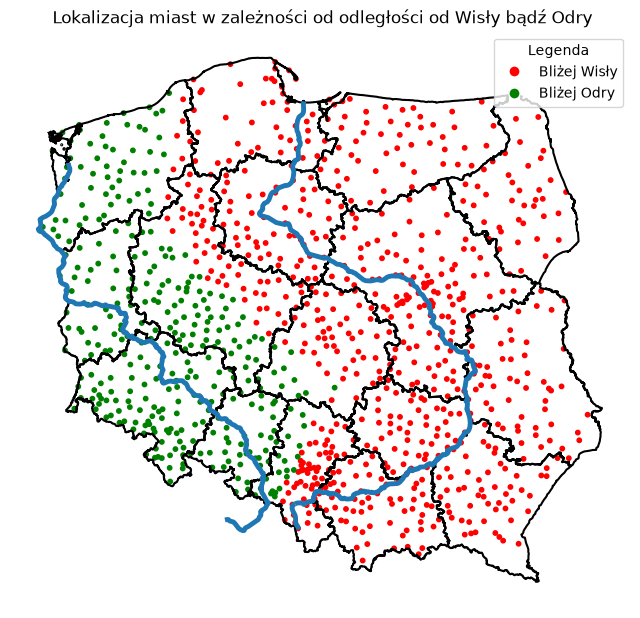

In [78]:
fig, ax = plt.subplots( 1,1, figsize = (8,8))
voivodeships.boundary.plot( ax = ax, color = "black" )
Wisła.plot( ax= ax, linewidth = 3.5 )
Odra.plot( ax = ax, linewidth = 3.5 )
cities.plot( ax = ax, markersize = 10, color = np.where( cities_nearest_river["bliższa rzeka"] == "Wisła", "red", "green" ), legend = True )
ax.set_axis_off()
ax.set_title(" Lokalizacja miast w zależności od odległości od Wisły bądź Odry" )

from matplotlib.lines import Line2D

legend_elements = [
    Line2D([0], [0], marker="o", color="w",
           markerfacecolor="red", markersize=8, label="Bliżej Wisły"),
    Line2D([0], [0], marker="o", color="w",
           markerfacecolor="green", markersize=8, label="Bliżej Odry")
]

ax.legend(handles=legend_elements, title="Legenda")

### Zadanie 3: Sąsiedztwo powiatów (6 pkt)

Korzystając z funkcji `geopandas.sjoin()`, przygotuj tablicę `neighbours`, zawierającą pary sąsiadujących ze sobą powiatów oraz zapisz liczbę sąsiadów każdego powiatu w kolumnie `liczba sąsiadów` tablicy `districts`.

Tablica `neighbours`:
> Indeks:<br>
> Indeksy powiatów z tablicy `districts`, powtarzające się dla kolejnych sąsiadów.

> Kolumny: TERYT powiatu, TERYT sąsiada, geometry<br>
> Kolumny zawierają kody TERYT powiatów, kody TERYT ich sąsiadów oraz geometrie powiatów wskazanych w kolumnie `TERYT powiatu`.

Następnie przygotuj mapę powiatów pokolorowanych według liczby sąsiadów.

Wizualizacja powinna zawierać:
- powiaty z widocznymi granicami i wypełnione kolorem powiązanym z liczbą sąsiadów (ciągła skala barw) oraz słupek skali barw,
- pogrubione granice województw, bez wypełnienia.

Przygotuj figurę zgodnie z wytycznymi z nagłówka notatnika. Ustaw parametry wykresu oraz wizualizowanych obiektów (wielkość figury, kolory, grubość linii, wielkość punktów itp.) tak, aby wygenerowana mapa była przejrzysta i czytelna.

Przykładowy schemat rozwiązania:
1) Wybierz z tablicy `districts` kolumny `TERYT` i `geometry`.
2) Połącz przygotowaną tablicę z nią samą funkcją `geopandas.sjoin()`. Dobierz `how` i `predicate`, aby otrzymać wyłącznie pary sąsiadujących powiatów. Wynik zapisz do zmiennej `neighbours`. W tablicy `neighbours` każda para sąsiadujących powiatów będzie występować dwukrotnie, ponieważ każdy z nich jest sąsiadem drugiego.
3) Korzystając z funkcji `pandas.DataFrame.rename()`, zmień nazwy kolumn `TERYT_left` i `TERYT_right` na odpowiednio `TERYT powiatu` i `TERYT sąsiada`. Wybierz kolumny w wymaganej kolejności, pomijając kolumnę `index_right`.
4) Korzystając z funkcji `pandas.Index.value_counts()`, policz sąsiadów każdego powiatu. Dopasuj wyniki do indeksu tablicy `districts` za pomocą `reindex()` i zapisz liczby całkowite w kolumnie `liczba sąsiadów`.
5) Przygotuj mapę.

In [79]:
districts2 = districts.iloc[:,[0,2]]
districts2 
neighbours = gpd.sjoin( districts2, districts, how = "left", predicate = "touches" )
neighbours.rename(inplace = True, columns={"TERYT_left" : "TERYT powiatu", "TERYT_right" : "TERYT sąsiada"  })
neighbours = neighbours[ ["TERYT powiatu", "TERYT sąsiada", "geometry" ]]
index = neighbours["TERYT powiatu"]
neighbours["liczba sąsiadów"] = neighbours.index.value_counts()
sasiedzi = neighbours.index.value_counts()
sasiedzi.reindex( districts2.index, fill_value = 0 )
districts["liczba sąsiadów"] = sasiedzi
neighbours = neighbours[["TERYT powiatu", "TERYT sąsiada", "geometry" ]] 
neighbours 

,TERYT powiatu,TERYT sąsiada,geometry
0,0201,0212,"MULTIPOLYGON (((250134.465 367561.308, 250165...."
0,0201,0210,"MULTIPOLYGON (((250134.465 367561.308, 250165...."
0,0201,0226,"MULTIPOLYGON (((250134.465 367561.308, 250165...."
0,0201,0225,"MULTIPOLYGON (((250134.465 367561.308, 250165...."
0,0201,0209,"MULTIPOLYGON (((250134.465 367561.308, 250165...."
...,...,...,...
378,3262,3206,"MULTIPOLYGON (((204268.991 619132.84, 204413.0..."
378,3262,3214,"MULTIPOLYGON (((204268.991 619132.84, 204413.0..."
378,3262,3211,"MULTIPOLYGON (((204268.991 619132.84, 204413.0..."
378,3262,3204,"MULTIPOLYGON (((204268.991 619132.84, 204413.0..."


In [80]:
# Komórka testowa
assert type(neighbours) == gpd.GeoDataFrame, "Zmienna neighbours powinna zawierać GeoDataFrame."
assert neighbours.shape == (2000, 3), "Niepoprawna liczba par sąsiadów lub kolumn."
assert list(neighbours.columns) == ["TERYT powiatu", "TERYT sąsiada", "geometry"], "Niepoprawne nazwy lub kolejność kolumn."
assert neighbours.crs == "epsg:2180", "Geometrie powinny być wyrażone w EPSG:2180."
assert neighbours["TERYT sąsiada"].isin(districts["TERYT"]).all(), "Kody sąsiadów nie odpowiadają tablicy districts."
assert np.array_equal(neighbours["TERYT powiatu"], districts.loc[neighbours.index, "TERYT"]), "Niepoprawne kody powiatów."
_pairs = set(zip(neighbours["TERYT powiatu"], neighbours["TERYT sąsiada"]))
assert len(_pairs) == len(neighbours) and all(a != b and (b, a) in _pairs for a, b in _pairs), "Pary sąsiadów powinny być unikalne, obustronne i bez połączeń powiatu z samym sobą."
assert "liczba sąsiadów" in districts and pd.api.types.is_integer_dtype(districts["liczba sąsiadów"]), "Brakuje całkowitych liczb sąsiadów."
assert np.array_equal(districts["liczba sąsiadów"], neighbours.index.value_counts().reindex(districts.index, fill_value=0)), "Niepoprawne liczby sąsiadów powiatów."
assert shp.touches(districts.loc[neighbours.index, "geometry"].to_numpy(), districts.set_index("TERYT").loc[neighbours["TERYT sąsiada"], "geometry"].to_numpy()).all(), "W tablicy neighbours znajdują się powiaty, które nie są sąsiadami."

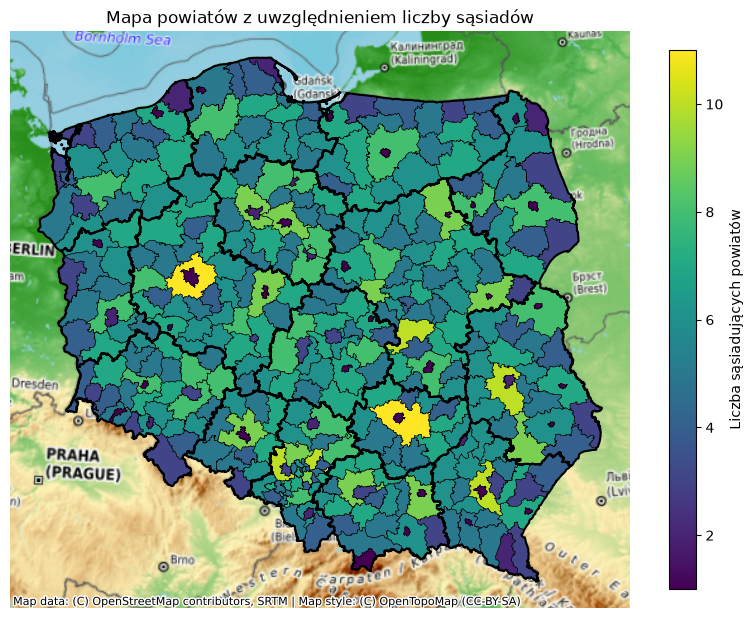

In [81]:
fig, ax = plt.subplots(1,1, figsize = (10,10))

voivodeships.boundary.plot(ax = ax, color = "black")
districts.plot(ax = ax,   column="liczba sąsiadów", cmap = "viridis", legend = True, legend_kwds = { "label" : "Liczba sąsiadujących powiatów", 
                                                                         "orientation" : "vertical", "shrink": 0.7  }, 
 edgecolor="black",  
    linewidth=0.4 )
ax.set_axis_off()
ax.set_title("Mapa powiatów z uwzględnieniem liczby sąsiadów")
cx.add_basemap( ax = ax, source = "OpenTopoMap", crs = "EPSG:2180")

### Zadanie 4: Kolorowanie sąsiadujących powiatów (6 pkt)

Korzystając z przygotowanej w poprzednim zadaniu tablicy `neighbours` oraz funkcji pakietu NetworkX, przypisz powiatom kolory tak, aby żadne dwa sąsiadujące powiaty nie miały tego samego koloru. Przygotuj graf sąsiedztwa `district_graph`, słownik `colors` przypisujący kodom `TERYT` numery kolorów oraz uzupełnij tablicę `districts` o kolumnę `kolor`.

Tablica `districts`:
> Indeks:  
> Indeksy powiatów z wejściowej tablicy `districts`.

> Kolumny: TERYT, powiat, liczba miast, liczba sąsiadów, kolor, geometry<br>
> Wszystkie kolumny wejściowej tablicy `districts` oraz dodatkowa kolumna `kolor`, zawierająca numery kolorów przypisanych poszczególnym powiatom.

Następnie za pomocą funkcji `print()` wyświetl pełnym zdaniem informację o liczbie wykorzystanych kolorów i przygotuj mapę pokolorowanych powiatów.

Wizualizacja powinna zawierać:
- powiaty z widocznymi granicami i wypełnieniem odpowiadającym kategoriom określonym przez kolumnę `kolor` (dyskretna skala barw).

Przygotuj figurę zgodnie z wytycznymi z nagłówka notatnika. Ustaw parametry wykresu oraz wizualizowanych obiektów (wielkość figury, kolory, grubość linii, wielkość punktów itp.) tak, aby wygenerowana mapa była przejrzysta i czytelna.

Przykładowy schemat rozwiązania:

1. Utwórz za pomocą funkcji `networkx.Graph()` pusty graf i zapisz go do zmiennej `district_graph`.
2. Korzystając z metody `networkx.Graph.add_nodes_from()`, dodaj do grafu wszystkie kody `TERYT` powiatów jako jego wierzchołki.
3. Korzystając z metody `networkx.Graph.add_edges_from()` oraz funkcji `zip()`, dodaj do grafu pary kodów z kolumn `TERYT powiatu` i `TERYT sąsiada` tablicy `neighbours` jako jego krawędzie.
4. Korzystając z funkcji `networkx.coloring.greedy_color()`, utwórz słownik przypisujący numery kolorów wierzchołkom grafu. Wykorzystaj strategię kolorowania `"largest_first"`. Zapisz wynik do zmiennej `colors`.
5. Za pomocą metody `pandas.Series.map()` przypisz numery kolorów odpowiednim powiatom i zapisz je w kolumnie `kolor` tablicy `districts`.
6. Policz liczbę wykorzystanych kolorów, wyświetl wynik zgodnie z instrukcją i przygotuj mapę.

In [82]:
district_graph = nx.Graph()
district_graph.add_nodes_from( neighbours["TERYT powiatu"] )
district_graph.add_edges_from( zip( neighbours["TERYT powiatu"], neighbours["TERYT sąsiada"] ))
colors = nx.coloring.greedy_color( district_graph, strategy = "largest_first" )
districts["kolor"] = districts["TERYT"].map( colors )
districts
liczba_kolorów = len(set(colors.values()))
print(f" Liczba wykorzystanych kolorów wynosi {liczba_kolorów} ")

 Liczba wykorzystanych kolorów wynosi 6 


In [83]:
# Komórka testowa
assert type(district_graph) == nx.Graph, "Zmienna district_graph powinna zawierać nieskierowany graf NetworkX."
assert set(district_graph.nodes) == set(districts["TERYT"]), "Graf powinien zawierać wszystkie powiaty identyfikowane kodami TERYT."
_expected_edges = {frozenset(pair) for pair in zip(neighbours["TERYT powiatu"], neighbours["TERYT sąsiada"])}
assert {frozenset(edge) for edge in district_graph.edges} == _expected_edges, "Krawędzie grafu nie odpowiadają sąsiedztwu powiatów."
assert isinstance(colors, dict) and set(colors) == set(district_graph.nodes), "Słownik colors powinien przypisywać kolor każdemu powiatowi."
assert "kolor" in districts.columns, "Tablica districts powinna zawierać kolumnę `kolor`"
assert np.array_equal(districts["kolor"], districts["TERYT"].map(colors)), "Kolory w tablicy nie odpowiadają słownikowi colors."
assert all(colors[a] != colors[b] for a, b in district_graph.edges), "Sąsiadujące powiaty nie mogą mieć tego samego koloru."

Text(0.5, 1.0, ' Mapa powiatów ')

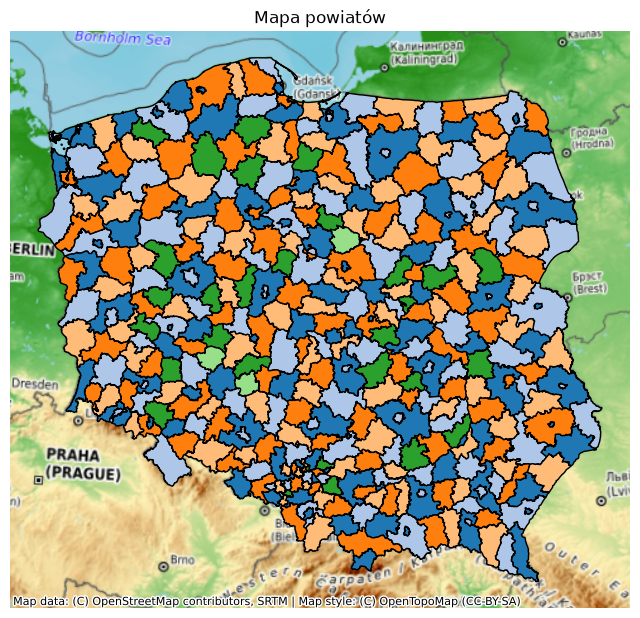

In [84]:
fig, ax = plt.subplots(1,1, figsize = (8,8))
districts.plot( ax = ax, column = "kolor", cmap = "tab20", edgecolor="black", categorical = True)
cx.add_basemap( ax = ax, source = "OpenTopoMap", crs = "EPSG:2180" )

ax.set_axis_off()
ax.set_title( " Mapa powiatów " )